# Anomaly detection & risk scoring: full analysis

**Project `spf-risk-scoring`**, built in response to the *Data Analyst (M/F/X), SPF Finances* vacancy (code AFG26149).

This notebook runs the analysis end to end: multi-source loading, exploration (EDA), quality checks,
feature engineering, anomaly detection (Isolation Forest), validation, and a supervised comparison.

> **Framing.** Public financial data (UCI *Default of Credit Card Clients*, 30,000 clients) used as a
> proxy for a risk-detection workflow. No real personal data. The production modules live in `src/`;
> this notebook is the narrative version.

## 1. Multi-source loading
One structured source (CSV) and one semi-structured source (JSON reference).

In [31]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)


ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: /Users/proftg/DataScience/Projets/spf-risk-scoring


In [22]:
# Source 1: structured CSV
df = pd.read_csv(ROOT / "data" / "raw" / "credit_default.csv")
df = df.rename(columns={"default payment next month": "default_flag", "PAY_0": "PAY_1"})

# Source 2: JSON reference (semi-structured)
with open(ROOT / "data" / "reference" / "segments.json", encoding="utf-8") as f:
    ref = json.load(f)

# Join the business labels
df["education_label"] = df["EDUCATION"].astype(str).map(ref["education_labels"])
df["marriage_label"] = df["MARRIAGE"].astype(str).map(ref["marriage_labels"])
df["sex_label"] = df["SEX"].astype(str).map(ref["sex_labels"])

print("Shape:", df.shape)
df.head()

Shape: (30000, 28)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_flag,education_label,marriage_label,sex_label
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1,university,married,female
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1,university,single,female
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0,university,single,female
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0,university,married,female
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0,university,married,male


## 2. Overview & quality checks
Types, missing values, duplicates, target balance.

In [32]:
print("Column types:")
print(df.dtypes.value_counts())
print("\nMissing values (excluding joined labels):", df.iloc[:, :25].isna().sum())
print("Duplicate identifiers:", df["ID"].duplicated().sum())
print("Age: min =", df.AGE.min(), "| max =", df.AGE.max())
print("\nTarget balance (default rate):")
print(df["default_flag"].value_counts(normalize=True).round(3))

Column types:
int64      27
object      3
float64     1
Name: count, dtype: int64

Missing values (excluding joined labels): ID              0
LIMIT_BAL       0
SEX             0
EDUCATION       0
MARRIAGE        0
AGE             0
PAY_1           0
PAY_2           0
PAY_3           0
PAY_4           0
PAY_5           0
PAY_6           0
BILL_AMT1       0
BILL_AMT2       0
BILL_AMT3       0
BILL_AMT4       0
BILL_AMT5       0
BILL_AMT6       0
PAY_AMT1        0
PAY_AMT2        0
PAY_AMT3        0
PAY_AMT4        0
PAY_AMT5        0
PAY_AMT6        0
default_flag    0
dtype: int64
Duplicate identifiers: 0
Age: min = 21 | max = 79

Target balance (default rate):
default_flag
0    0.779
1    0.221
Name: proportion, dtype: float64


## 3. Exploratory data analysis (EDA)

We look for trends, correlations and profiles associated with payment default.

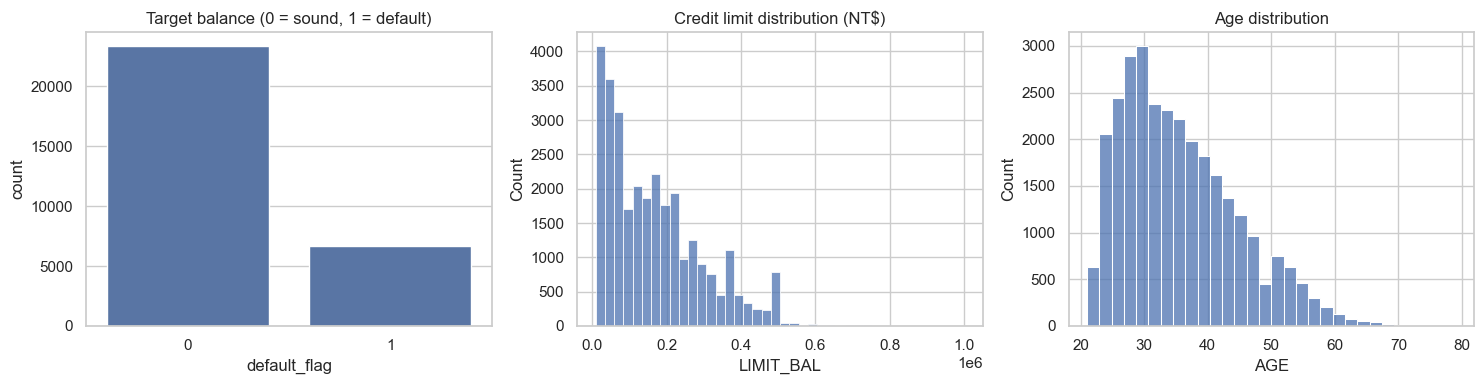

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="default_flag", ax=axes[0])
axes[0].set_title("Target balance (0 = sound, 1 = default)")
sns.histplot(df["LIMIT_BAL"], bins=40, ax=axes[1])
axes[1].set_title("Credit limit distribution (NT$)")
sns.histplot(df["AGE"], bins=30, ax=axes[2])
axes[2].set_title("Age distribution")
plt.tight_layout()
plt.show()

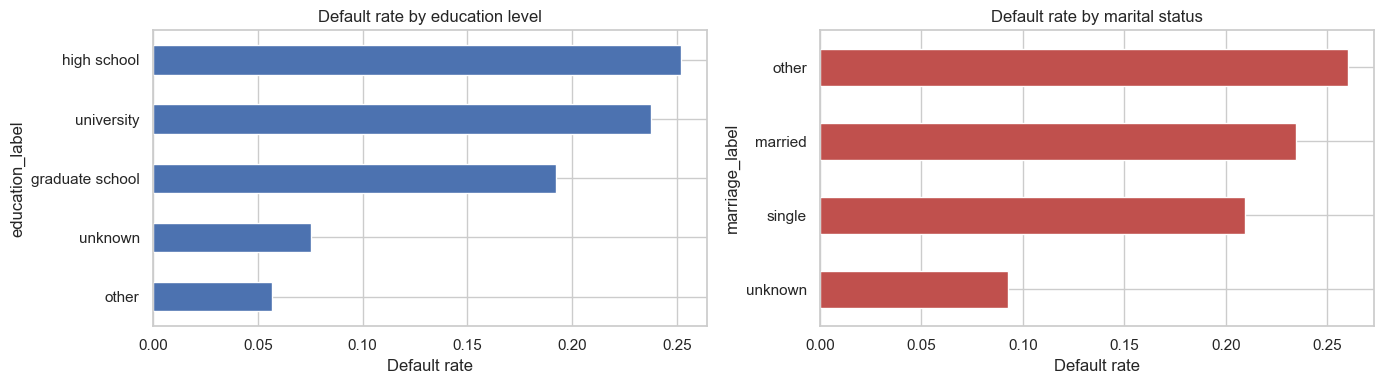

In [34]:
# Default rate per business segment
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby("education_label")["default_flag"].mean().sort_values()
   .plot.barh(ax=axes[0], title="Default rate by education level"))
(df.groupby("marriage_label")["default_flag"].mean().sort_values()
   .plot.barh(ax=axes[1], title="Default rate by marital status", color="#c0504d"))
for ax in axes:
    ax.set_xlabel("Default rate")
plt.tight_layout()
plt.show()

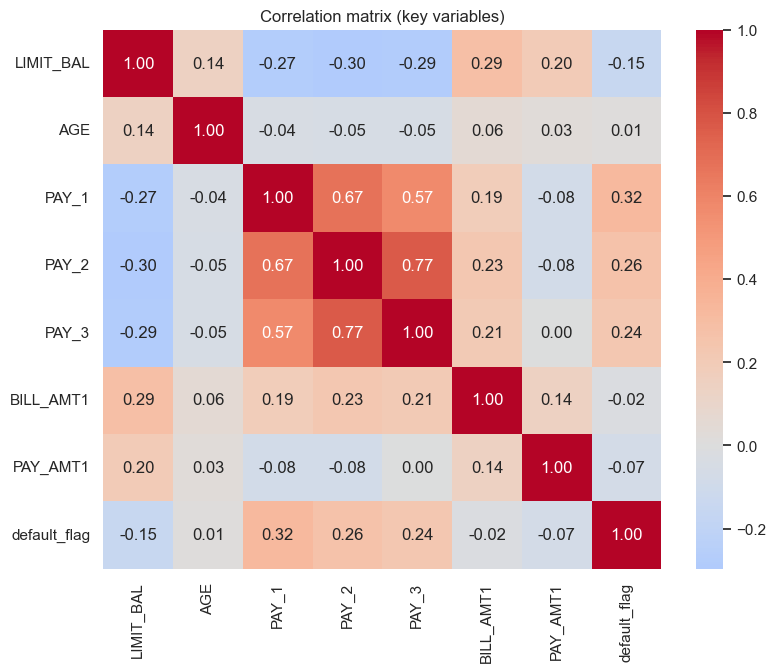

In [35]:
# Correlations between key variables
cols = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_3",
        "BILL_AMT1", "PAY_AMT1", "default_flag"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (key variables)")
plt.show()

**Quick read:** payment-delay variables (`PAY_1`..`PAY_3`) are the most correlated with default.
The credit limit is negatively correlated (higher limits mean safer profiles).

## 4. Feature engineering

We aggregate the 18 monthly columns into usable synthetic features.
We **reuse the production function** `src/scoring.py` (single source of truth, no duplication).

In [36]:
from src.scoring import engineer_features

feats = engineer_features(df)
print("Features built:", list(feats.columns))
feats.describe().round(2)

Features built: ['limit_bal', 'age', 'avg_bill', 'avg_pay', 'utilization', 'n_delays', 'max_delay', 'repayment_ratio']


,limit_bal,age,avg_bill,avg_pay,utilization,n_delays,max_delay,repayment_ratio
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,167484.32,35.49,44976.95,5275.23,0.37,0.83,0.68,0.36
std,129747.66,9.22,63260.72,10137.95,0.35,1.55,1.07,0.50
min,10000.00,21.00,-56043.17,0.00,-0.23,0.00,0.00,-0.00
25%,50000.00,28.00,4781.33,1113.29,0.03,0.00,0.00,0.04
50%,140000.00,34.00,21051.83,2397.17,0.28,0.00,0.00,0.08
75%,240000.00,41.00,57104.42,5583.92,0.69,1.00,2.00,0.59
max,1000000.00,79.00,877313.83,627344.33,5.00,6.00,8.00,3.00


## 5. Anomaly detection with Isolation Forest

**Unsupervised** approach: we flag atypical profiles **without using the target**.
Isolation Forest isolates rare points in few splits. We derive a 0-100 risk score from it.

In [37]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(feats.values)
model = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
model.fit(X)

raw = model.score_samples(X)           # lower = more atypical
risk = 100 * (raw.max() - raw) / (raw.max() - raw.min())

df["risk_score"] = risk.round(1)
df["anomaly"] = (model.predict(X) == -1).astype(int)
df["risk_decile"] = pd.qcut(df["risk_score"], 10, labels=False, duplicates="drop") + 1

print("Anomalies detected:", int(df["anomaly"].sum()), f"({df['anomaly'].mean():.1%})")
df[["ID", "risk_score", "anomaly", "default_flag"]].head()

Anomalies detected: 1500 (5.0%)


,ID,risk_score,anomaly,default_flag
0,1,21.1,0,1
1,2,19.4,0,1
2,3,1.0,0,0
3,4,5.5,0,0
4,5,29.2,0,0


## 6. Score validation

The model never saw the target. If the score is meaningful, the **real default rate should increase
with the risk score**. That is the validity test.

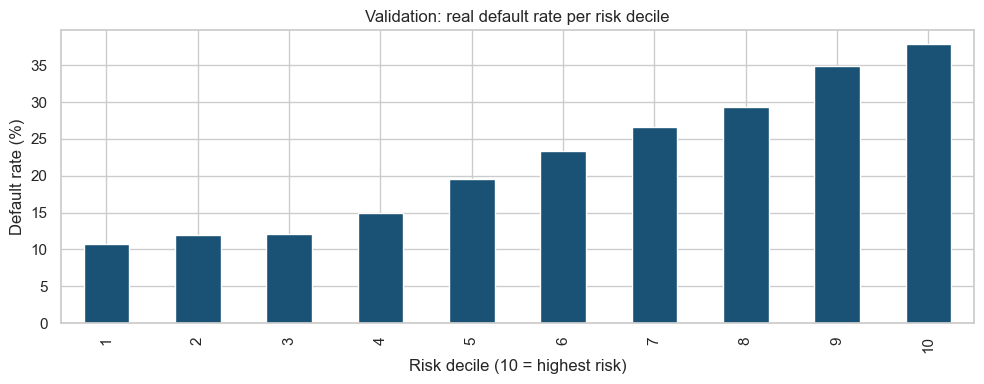

Default rate: global = 22.1% | anomalies = 35.5% (lift x1.61)
Monotonically increasing: True


In [38]:
by_dec = df.groupby("risk_decile")["default_flag"].mean() * 100

ax = by_dec.plot.bar(figsize=(10, 4), color="#1a5276")
ax.set_title("Validation: real default rate per risk decile")
ax.set_xlabel("Risk decile (10 = highest risk)")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

lift = df.loc[df.anomaly == 1, "default_flag"].mean() / df["default_flag"].mean()
print(f"Default rate: global = {df.default_flag.mean():.1%} "
      f"| anomalies = {df.loc[df.anomaly==1,'default_flag'].mean():.1%} (lift x{lift:.2f})")
print(f"Monotonically increasing: {(by_dec.diff().dropna() >= 0).all()}")

## 7. Supervised vs unsupervised comparison

An anomaly is not a default: Isolation Forest flags the atypical, not the risky.
To cover both sides of the vacancy (*scoring* and *risk detection*), we compare the unsupervised
anomaly score with a simple supervised model (logistic regression) that learns default directly.
We measure ranking ability with the AUC.

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

idx_tr, idx_te = train_test_split(df.index, test_size=0.3, random_state=42,
                                  stratify=df["default_flag"])
clf = LogisticRegression(max_iter=1000).fit(X[idx_tr], df.loc[idx_tr, "default_flag"])

auc_sup = roc_auc_score(df.loc[idx_te, "default_flag"], clf.predict_proba(X[idx_te])[:, 1])
auc_ano = roc_auc_score(df.loc[idx_te, "default_flag"], df.loc[idx_te, "risk_score"])

print(f"AUC supervised scoring (logistic regression) : {auc_sup:.3f}")
print(f"AUC anomaly detection (Isolation Forest)     : {auc_ano:.3f}")

AUC supervised scoring (logistic regression) : 0.743
AUC anomaly detection (Isolation Forest)     : 0.651


## 8. Conclusions

- **Full pipeline** validated: multi-source ingestion, quality, feature engineering, scoring, validation.
- The unsupervised risk score **separates risk**: the default rate goes from about 11% (decile 1) to
  about 38% (decile 10), monotonically. Flagged anomalies default about 1.6x more than average.
- **Honest comparison:** a supervised model (logistic regression, AUC 0.743) ranks default better than
  the unsupervised anomaly score (AUC 0.651). The two approaches are complementary: detect the atypical,
  and score the risk.
- **Link to the SPF Finances vacancy (AFG26149):** this notebook demonstrates the *statistical and
  exploratory analysis* and the *contribution to scoring and risk-detection models* listed in the job.

The industrialized version (modules in `src/`, SQL quality checks, Streamlit dashboard) runs with
`python run.py` then `streamlit run app.py`.